# 03 · O salário real subiu ou caiu?

Valores em **reais de novembro de 2025** (IPCA, `salarios/ipca.py`), só quem
mora no Brasil. A pergunta tem uma armadilha: **quem responde a pesquisa
mudou** — mais velho, mais estudado, mais sênior (caderno 01). A mediana de
todo mundo pode subir sem que ninguém ganhe mais, só porque o grupo que
responde ficou mais experiente. Por isso o caderno mede de três jeitos, do
mais cru ao mais controlado.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from salarios.estatistica import RegressaoIntervalar, ic_bootstrap, mediana_agrupada
from salarios.graficos import AZUL, LARANJA, NIVEIS, TINTA_2, estilo, eixo_reais, reais
from salarios.ipca import fator

estilo()
df = pd.read_parquet("../dados/tratados/respostas.parquet")
br = df[(df["situacao"] != "Fora do Brasil") & df["sal_min"].notna()].copy()
br["fator_ipca"] = br["ano"].map(fator)
br["real_min"], br["real_max"] = br["sal_min"] * br["fator_ipca"], br["sal_max"] * br["fator_ipca"]
br.groupby("ano")["fator_ipca"].first().round(3).rename("multiplicador até nov/2025")

ano
2019    1.403
2021    1.215
2022    1.147
2023    1.096
2024    1.045
2025    1.000
Name: multiplicador até nov/2025, dtype: float64

## 1. A mediana de todo mundo

,nominal,real (R$ nov/2025),respostas
ano,,,
2019,5080.0,7120.0,1527
2021,7260.0,8810.0,2338
2022,7540.0,8640.0,3648
2023,8320.0,9120.0,4689
2024,9700.0,10130.0,4786
2025,10560.0,10560.0,3161


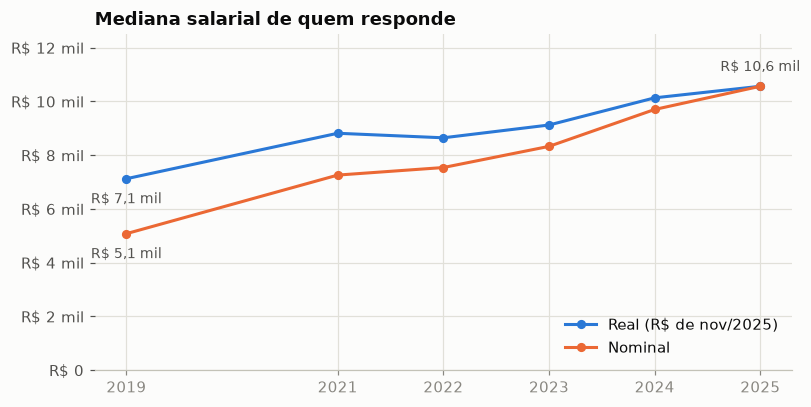

In [2]:
geral = pd.DataFrame({
    "nominal": br.groupby("ano").apply(lambda g: mediana_agrupada(g.sal_min, g.sal_max), include_groups=False),
    "real (R$ nov/2025)": br.groupby("ano").apply(lambda g: mediana_agrupada(g.real_min, g.real_max), include_groups=False),
    "respostas": br.groupby("ano").size(),
})
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for col, cor, rotulo in [("real (R$ nov/2025)", AZUL, "Real (R$ de nov/2025)"), ("nominal", LARANJA, "Nominal")]:
    ax.plot(geral.index, geral[col], marker="o", markersize=5, color=cor, label=rotulo)
    # rótulo seletivo: o ponto de partida; em 2025 as duas linhas coincidem por definição
    ax.annotate(reais(geral[col].iloc[0]), (geral.index[0], geral[col].iloc[0]), xytext=(0, -16),
                textcoords="offset points", ha="center", color=TINTA_2, fontsize=9)
ax.annotate(reais(geral["nominal"].iloc[-1]), (geral.index[-1], geral["nominal"].iloc[-1]), xytext=(0, 10),
            textcoords="offset points", ha="center", color=TINTA_2, fontsize=9)
ax.legend(loc="lower right")
ax.set_xticks(geral.index)
eixo_reais(ax, "y")
ax.set_ylim(0, 12500)
ax.set_title("Mediana salarial de quem responde")
plt.tight_layout()
geral.assign(**{c: geral[c].round(-1) for c in ["nominal", "real (R$ nov/2025)"]})

Em termos reais, a mediana foi de R$ 7,1 mil (2019) para R$ 10,6 mil (2025).
Parece um ganho de 48% acima da inflação — mas é a mediana de **grupos
diferentes de pessoas**. A de 2019 vem de outro questionário (sem pergunta
de nível, anonimização mais forte), e a composição mudou muito:

In [3]:
com_nivel = br[br["nivel_comparavel"].notna()]
composicao = pd.crosstab(com_nivel["ano"], com_nivel["nivel_comparavel"], normalize="index").mul(100).round(1)
composicao

nivel_comparavel,Júnior,Pleno,Sênior
ano,,,
2021,33.7,35.5,30.8
2022,34.6,35.5,29.9
2023,27.2,36.2,36.6
2024,22.9,36.1,41.0
2025,21.0,31.0,48.0


Os sêniores eram 30,8% de quem informou nível em 2021 e são 48,0% em 2025.
Sênior ganha mais; mais sênior na amostra puxa a mediana para cima.

## 2. Dentro de cada nível

nivel_comparavel,Júnior,Pleno,Sênior
ano,,,
2021,4030.0,8150.0,12940.0
2022,3920.0,7990.0,13040.0
2023,3800.0,7380.0,12990.0
2024,3660.0,7540.0,13400.0
2025,3480.0,7460.0,13660.0


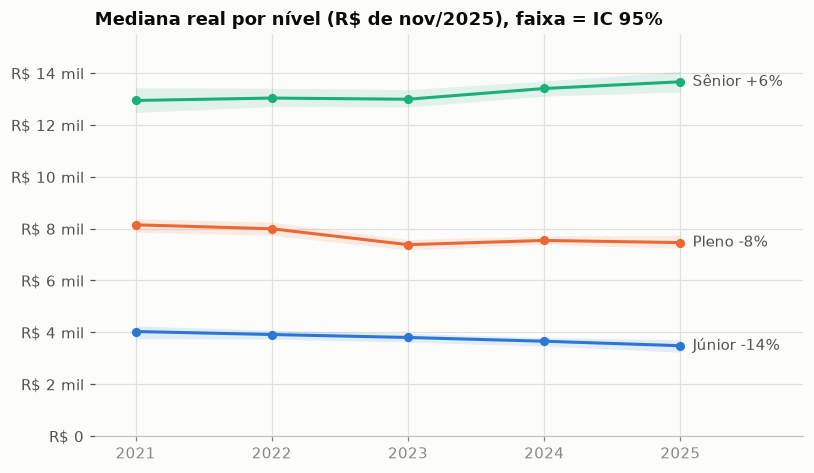

In [4]:
def mediana_ic(g):
    a, b = ic_bootstrap(g.real_min.to_numpy(), g.real_max.to_numpy(), n=500)
    return pd.Series({"mediana": mediana_agrupada(g.real_min, g.real_max), "ic_baixo": a, "ic_alto": b, "n": len(g)})


por_nivel = (com_nivel.groupby(["nivel_comparavel", "ano"], observed=True)
             .apply(mediana_ic, include_groups=False).reset_index())

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for nivel, cor in NIVEIS.items():
    t = por_nivel[por_nivel["nivel_comparavel"] == nivel]
    ax.fill_between(t["ano"], t["ic_baixo"], t["ic_alto"], color=cor, alpha=0.12, linewidth=0)
    ax.plot(t["ano"], t["mediana"], marker="o", markersize=5, color=cor)
    ini, fim = t["mediana"].iloc[0], t["mediana"].iloc[-1]
    ax.annotate(f"{nivel} {fim / ini - 1:+.0%}", (t["ano"].iloc[-1], fim), xytext=(8, 0),
                textcoords="offset points", va="center", color=TINTA_2)
ax.set_xticks(sorted(por_nivel["ano"].unique()))
ax.set_xlim(2020.7, 2025.9)
eixo_reais(ax, "y")
ax.set_ylim(0, 15500)
ax.set_title("Mediana real por nível (R$ de nov/2025), faixa = IC 95%")
plt.tight_layout()
(por_nivel.pivot(index="ano", columns="nivel_comparavel", values="mediana").round(-1))

Dentro do nível, a história se inverte. De 2021 a 2025, em termos reais:

- **Júnior: de R$ 4,0 mil para R$ 3,5 mil (−14%)**, com intervalos que não
  se encostam (R$ 3,8–4,2 mil em 2021; R$ 3,2–3,7 mil em 2025).
- **Pleno: de R$ 8,1 mil para R$ 7,5 mil (−8%)**, também sem sobreposição.
- **Sênior: de R$ 12,9 mil para R$ 13,7 mil (+6%).**

A alta da mediana geral vem quase toda de haver mais sêniores, não de
sêniores ganhando mais. E quem está começando ganha menos, em poder de
compra, do que ganhava em 2021.

## 3. Mesmo perfil, anos diferentes

O nível sozinho ainda deixa coisa de fora: experiência, cargo, estado e
escolaridade também mudaram. A regressão por intervalo
(`salarios/estatistica.py`) estima o efeito de cada ano **com tudo isso
fixo**. Gestores ficam num modelo à parte: para eles a pesquisa não pergunta
cargo nem nível, e sim o nível de gestão.

A edição de 2019 fica fora: não perguntou o nível.

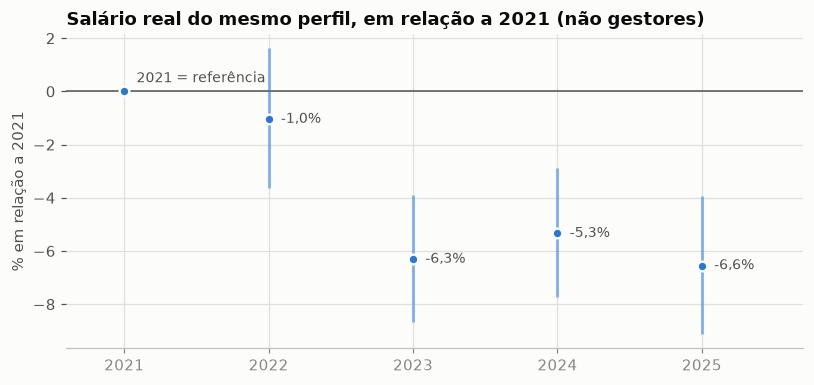

In [5]:
d = br[(br["ano"] >= 2021) & br["familia"].notna()].dropna(subset=["exp_anos", "ensino"]).copy()
d["uf_grupo"] = d["uf"].astype(str).where(d["uf"].isin(["SP", "MG", "RJ", "PR", "RS", "SC", "DF"]), "outros")
d["ano_c"] = d["ano"].astype(str)
d = d.assign(sal_min=d["real_min"], sal_max=d["real_max"])
contribuidores, gestores = d[d["familia"] != "Gestor"], d[d["familia"] == "Gestor"]
CONTROLES = "C(uf_grupo) + C(ensino)"

especificacoes = {
    "principal: cargo, nível, experiência, estado, escolaridade":
        (contribuidores, f"C(ano_c) + C(familia) + C(nivel_comparavel) + exp_anos + I(exp_anos**2) + {CONTROLES}"),
    "experiência em faixa, em vez de anos":
        (contribuidores, f"C(ano_c) + C(familia) + C(nivel_comparavel) + C(exp_faixa) + {CONTROLES}"),
    "só CLT":
        (contribuidores[contribuidores["situacao"] == "CLT"],
         f"C(ano_c) + C(familia) + C(nivel_comparavel) + exp_anos + I(exp_anos**2) + {CONTROLES}"),
    "sem controlar experiência":
        (contribuidores, f"C(ano_c) + C(familia) + C(nivel_comparavel) + {CONTROLES}"),
    "sem controlar nível nem experiência":
        (contribuidores, f"C(ano_c) + C(familia) + {CONTROLES}"),
    "gestores (nível de gestão, experiência, estado, escolaridade)":
        (gestores, f"C(ano_c) + C(gestor_nivel) + exp_anos + I(exp_anos**2) + {CONTROLES}"),
}
modelos = {nome: RegressaoIntervalar(f, dados).ajustar() for nome, (dados, f) in especificacoes.items()}


def efeitos_do_ano(m):
    e = m.efeitos()
    e = e[e.index.str.startswith("C(ano_c)")]
    e.index = [int(i[-5:-1]) for i in e.index]
    return e


principal = efeitos_do_ano(modelos["principal: cargo, nível, experiência, estado, escolaridade"])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axhline(0, color=TINTA_2, linewidth=1)
ax.vlines(principal.index, principal["ic_baixo"] * 100, principal["ic_alto"] * 100, color=AZUL, linewidth=2, alpha=0.5)
ax.scatter(principal.index, principal["efeito"] * 100, color=AZUL, s=40, zorder=3, edgecolor="white", linewidth=1.5)
for ano, r in principal.iterrows():
    ax.annotate(f"{r['efeito']:+.1%}".replace(".", ","), (ano, r["efeito"] * 100), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
ax.scatter([2021], [0], color=AZUL, s=40, zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate("2021 = referência", (2021, 0), xytext=(8, 6), textcoords="offset points", fontsize=9, color=TINTA_2)
ax.set_xticks([2021, 2022, 2023, 2024, 2025])
ax.set_xlim(2020.6, 2025.7)
ax.set_ylabel("% em relação a 2021")
ax.set_title("Salário real do mesmo perfil, em relação a 2021 (não gestores)")
plt.tight_layout()

In [6]:
pd.DataFrame({
    nome: {
        "respostas": m.n,
        "2025 vs 2021": "{:+.1%} [{:+.1%}, {:+.1%}]".format(*efeitos_do_ano(m).loc[2025, ["efeito", "ic_baixo", "ic_alto"]]),
        "2024": "{:+.1%}".format(efeitos_do_ano(m).loc[2024, "efeito"]),
        "2023": "{:+.1%}".format(efeitos_do_ano(m).loc[2023, "efeito"]),
        "2022": "{:+.1%}".format(efeitos_do_ano(m).loc[2022, "efeito"]),
    } for nome, m in modelos.items()
}).T

,respostas,2025 vs 2021,2024,2023,2022
"principal: cargo, nível, experiência, estado, escolaridade",14769,"-6.6% [-9.1%, -3.9%]",-5.3%,-6.3%,-1.0%
"experiência em faixa, em vez de anos",14769,"-8.1% [-10.7%, -5.5%]",-7.4%,-8.3%,-3.0%
só CLT,11574,"-6.0% [-8.4%, -3.4%]",-4.1%,-5.3%,-0.1%
sem controlar experiência,14769,"-3.6% [-6.3%, -0.8%]",-3.1%,-4.6%,-0.5%
sem controlar nível nem experiência,14769,"+10.4% [+6.5%, +14.6%]",+6.6%,+0.7%,-0.8%
"gestores (nível de gestão, experiência, estado, escolaridade)",3822,"+5.1% [-1.3%, +12.0%]",+9.3%,+5.5%,+5.2%


**Para o mesmo perfil, o salário real de quem não é gestor caiu de 6% a 8%
entre 2021 e 2025**, dependendo de como a experiência entra no modelo, e
nenhum intervalo cruza o zero. A queda aparece já em 2023 e não se recupera.

As duas últimas linhas mostram o mecanismo: tirando o controle de
experiência, a queda encolhe para 3,6%; tirando também o de nível, vira uma
**alta de 10,4%** — a mesma ilusão da mediana geral. Quem responde em 2025
é mais experiente, e é isso que a mediana bruta mede.

Para gestores o ano não mostra efeito claro (+5,1%, com intervalo de −1,3%
a +12,0%).

## O que isso permite dizer, e o que não

- **Permite:** entre quem responde a pesquisa, uma pessoa com o mesmo cargo,
  nível, experiência, estado e escolaridade declarava, em 2025, uma faixa
  salarial que vale de 6% a 8% menos em poder de compra que em 2021. Júnior
  e pleno perderam; sênior manteve ou ganhou um pouco.
- **Não permite:** dizer que o mercado inteiro pagou menos. A amostra é
  autosselecionada, e a seleção pode ter mudado: se em 2025 respondem mais
  juniores vindos de cursos rápidos, que ganham menos, a queda do júnior
  pode ser em parte de quem responde, não do salário de quem já estava lá.
- **Não permite:** comparar com 2019 com o mesmo controle — a edição não
  perguntou nível.
- **Nível é autodeclarado** e o que conta como "sênior" pode ter mudado entre
  empresas e anos; a experiência, também declarada, ajuda a amarrar isso.